In [7]:
import numpy as np
import random
import scipy.special
from scipy.special import factorial
import matplotlib.pyplot as plt

Final count of particles on the left: 517
Final count of particles on the right: 483
The standard deviation of the fluctuations is: 15.811388300841896


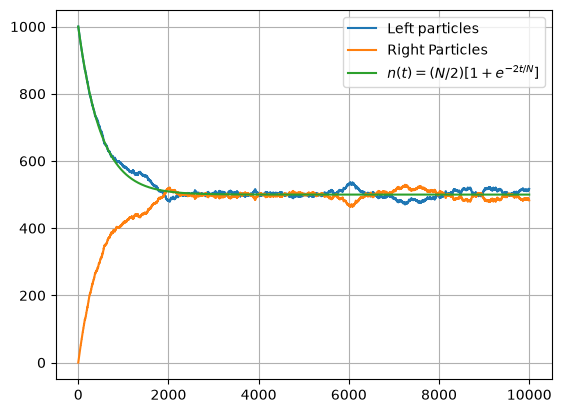

In [2]:
N = 1000                                                    # number of particles
t_max = 10000                                               # number of steps
time_step = 1                                               # step interval
k_b = 1.380649e-23                                          # Boltzmann constant for entropy calculation

pstate = np.zeros(N)                                        # state vector
time_points = np.arange(0, t_max, time_step)                # x-axis for plotting
left_points = []                                            # empty array for left y-values
right_points = []                                           # empty array for right y-values
entropy = []

# Main Loop
for i in range(t_max):
    
    n = np.count_nonzero(pstate == 0)                       # keeps track of # particles on the left
    n_right = np.count_nonzero(pstate)                      # keeps track of # particles on the right
    e_coeff =  scipy.special.binom(N, n)
    
    left_points.append(n)
    right_points.append(n_right)
    entropy.append(e_coeff)
    
    rnd = np.random.choice(N)                               # selects a random particle in the box - confirmed w/ numpy documentation that
                                                            # each choice has equal (1/N) probability

    if pstate[rnd] == 0:                                    # if particle is on the left, calculates transition prob to right
        if np.random.random() < (n / N):                    # then we generate a random number - if it's smaller than my transition probability
            pstate[rnd] = 1                                 # then the particles moves to the right
    else:
        if np.random.random() < (1 - (n / N)):              # if the particle is on the right, it's a different probability
            pstate[rnd] = 0                                 # and the state changes to left if transition probability > random number

# print(pstate)
print("Final count of particles on the left:", n)
print("Final count of particles on the right:", n_right)
print("The standard deviation of the fluctuations is:", np.sqrt(N)/2)

# Plotting
plt.plot(time_points, left_points)
plt.plot(time_points, right_points)
plt.plot(time_points, (N / 2) * (1 + np.exp((-2*time_points) / N)))
plt.grid(True)
plt.legend(['Left particles', 'Right Particles', '$n(t) = (N/2)[ 1 + e^{-2t/N}]$'])

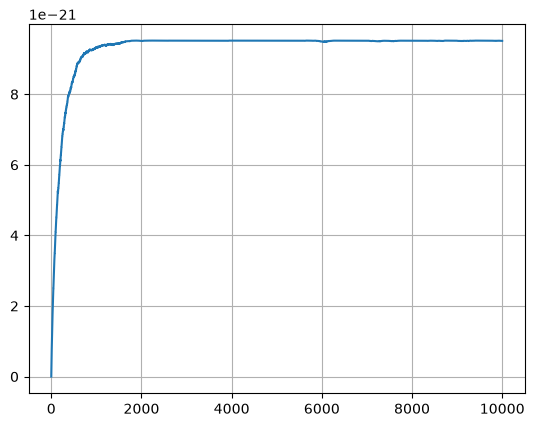

In [6]:
plt.plot(time_points, (k_b * np.log(entropy)))
plt.grid(True)

So my reasoning is that I create an array that represents the state of the system at t=0. All the particles are on the left (0) side of the box, and the idea is that we will select an entry of this array pstate[i] at random (which is the same as selecting a particle at random), calculate its probability to cross to the right side, and if it does, update its state to 1. IF the state of the system is 0, we calculate its probability of moving over to the right as n/N. IF the state of the system is 1, we calculate it's probability of moving over to the left using 1 - n/N. \
\
At every step of the way, I need to "count" how many entries are in state 0. I also want to plot this number over time. \
\
How the hell do I determine when to stop the loop?? (ie. when equilibrium has been reached).\
\
Well, I first I will define the number of steps (t = # steps).
N as we know is the number of particles.



# Concepts
Two types of statistical indepedence: \
* Memorylessness: probability of transitioning from one side to the box to the other is completely independent from the amount of time the particle has been on the former.
* Ensemble: each particle is chosen completely at random, regardless of which side of the box it is in.
* Reversibility paradox (find out more): while each step is technically microscopically reversible, when n >> N/2 it is MUCH more likely that a particle will go from l -> r than from r -> l

From the paper: \
The expectation value of the left side: \
$$ \langle \Delta n \rangle = (-1) \cdot \mathbb{P}(L \to R) + (+1) \cdot \mathbb{P}(R \to L) $$
Therefore:
$$ \langle \Delta n \rangle = - \frac{n}{N} + \frac{N - n}{N} $$
$$ \langle \Delta n \rangle = - \frac{n}{N} + \left(1 - \frac{n}{N}\right) $$
$$ \Delta n = \left[ 1 - 2 \left(\frac{n(t)}{N}\right) \right] \Delta t $$
Which as $\Delta t \to 0$:
$$\frac{dn}{dt}= 1 - \frac{2n(t)}{N} $$